# Alignment in Depth

A tilt series must be aligned before it is reconstructed: the specimen drifts between
projections, and the tilt axis is rarely exactly where the reconstruction assumes it is (centered,
and parallel to the stack x-axis). This notebook measures each of ETSpy's alignment tools against
a simulated tilt series whose misalignment is known exactly.

Topics covered:

* How to score an alignment, and which parts of it cannot be determined from the data
* The four registration methods of `stack_register`, and Fourier against spline interpolation of
  the shifts
* Finding the tilt axis with `tilt_align`, and checking it with `test_align`
* Repairing a single jump in a series with `manual_align`
* Applying the alignment of one signal to another acquired at the same time, with `align_other`

For the highest accuracy, projection matching refines the alignment further; it has its own
[notebook](projection_matching_demo.ipynb).

## Imports

In [1]:
%matplotlib inline

import time

import matplotlib.pyplot as plt
import numpy as np
import hyperspy.api as hs

import etspy.api as tomo
from etspy import align
from etspy import simulation as sim

tomo.set_log_level("WARNING")

## A Test Series with Known Misalignment

`create_alignment_test_series` simulates a tilt series of a phantom with features that are sharp
in every direction (particles, boxes, plates and rods on a thin support), then misaligns it with
random jitter plus a slow drift, and rotates the tilt axis. It returns:

* `misaligned`: the series to align, here with shot noise (`dose` counts per pixel in vacuum)
* `aligned`: the ideal series, without misalignment or noise
* `shifts`: the (Y, X) shifts that correct the misalignment of each projection, in pixels
* `tilt_axis`: the in-plane rotation (degrees) that corrects the tilt axis direction

The series covers 180$\degree$ in 2$\degree$ steps, and the tilt axis is rotated by 1$\degree$. Like
real data, the projections have a background (the vacuum level, here 0.2), which is removed with
`remove_background` before anything else; a background left in the data reconstructs as a ring
of wrong intensity.

In [37]:
series = sim.create_alignment_test_series(
    tilts=np.arange(-90, 90, 2.0),
    blur=0.5,
)
tilts = series.misaligned.tilts.data.squeeze()
stack = series.misaligned.remove_background()
print(stack)
print(f"true tilt axis rotation: {series.tilt_axis} degrees")
print(f"rms of the true shifts (Y, X): {np.sqrt((series.shifts**2).mean(0)).round(2)} px")

<TomoStack, title: , dimensions: (90|128, 128)>
true tilt axis rotation: 1.0 degrees
rms of the true shifts (Y, X): [1.71 3.21] px


In [38]:
series = sim.create_alignment_test_series(
    shape=(160, 160),
    tilts=np.arange(-90, 90, 2.0),
    max_shift=3.0,
    drift=2.0,
    tilt_axis=1.0,
    blur=0.5,
    dose=200,
    seed=2,
)
tilts = series.misaligned.tilts.data.squeeze()
stack = series.misaligned.remove_background()
print(stack)
print(f"true tilt axis rotation: {series.tilt_axis} degrees")
print(f"rms of the true shifts (Y, X): {np.sqrt((series.shifts**2).mean(0)).round(2)} px")

<TomoStack, title: , dimensions: (90|160, 160)>
true tilt axis rotation: 1.0 degrees
rms of the true shifts (Y, X): [2.32 1.86] px


In [39]:
np.argmin(abs(tilts))

np.int64(45)

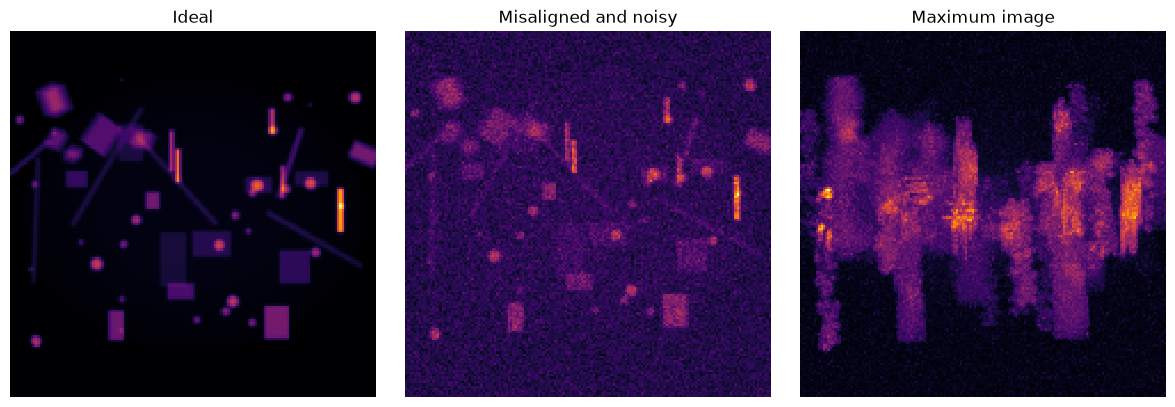

In [42]:
hs.plot.plot_images(
    [series.aligned.inav[45], stack.inav[45], stack.max()],
    per_row=3, cmap="inferno", axes_decor="off", colorbar=None,
    label=[r"Ideal", r"Misaligned and noisy", "Maximum image"],
)
plt.gcf().set_size_inches(12, 4)
plt.tight_layout()

## Registration Methods

`stack_register` aligns each projection with its neighbour, working outwards from the central one
(or from `start`):

| Method | How it works | Suited to |
|---|---|---|
| `"PC"` | Phase correlation of neighbouring projections | General use; fast |
| `"StackReg"` | Intensity-based registration (pystackreg) | General use; robust |
| `"COM"` | Center of mass tracking perpendicular to the tilt axis | Isolated objects that stay in the field of view |
| `"COM-CL"` | Center of mass perpendicular to the axis, common line along it | Isolated objects, such as needles and particles |

Registering neighbours lets small errors accumulate along the series, and it cannot see a
misplaced tilt axis: those are the job of `tilt_align` and projection matching.

### Scoring an Alignment

Some parts of the shifts cannot be found from the data, because they leave the reconstruction
unchanged apart from a translation within the 3D reconstructed volume.  These types of shifts are:

* Global shift along the tilt axis (X) will only move the reconstruction along the axis
* A shift perpendicular to the axis (Y) of the form b cos $\theta$ + c sin $\theta$ will only move the
  reconstruction within each slice

A global Y shift moves the tilt axis away from the center of the stack, which produces artifacts in the
reconstruction. But registration cannot find it, because it only compares projections with each
other.  Correcting the tilt-axis offset and rotation is done using the `tilt_align` method (see below).
So the errors of the registration methods can only be compared after removing all three parts.

In [46]:
def shift_errors(found, truth=series.shifts, tilts=tilts):
    """RMS error (px) of (Y, X) shifts, without the parts that cannot be determined."""
    theta = np.deg2rad(tilts)
    basis = np.array([np.ones_like(theta), np.cos(theta), np.sin(theta)]).T
    dy = found[:, 0] - truth[:, 0]
    dy = dy - basis @ np.linalg.lstsq(basis, dy, rcond=None)[0]
    dx = found[:, 1] - truth[:, 1]
    dx = dx - np.median(dx)
    return np.sqrt(np.mean(dy**2)), np.sqrt(np.mean(dx**2))

In [52]:
results = {}
results["None"] = (*shift_errors(np.zeros_like(series.shifts)), 0.0)
for method in ["PC", "StackReg", "COM", "COM-CL"]:
    t0 = time.perf_counter()
    reg = stack.stack_register(method)
    results[method] = (*shift_errors(reg.shifts.data), time.perf_counter() - t0)

print(f"{'method':9s} {'Y error (px)':>12s} {'X error (px)':>12s} {'time (s)':>9s}")
# print("no alignment: Y %.2f px, X %.2f px" % shift_errors(np.zeros_like(series.shifts)))
for method, (ey, ex, sec) in results.items():
    print(f"{method:9s} {ey:12.2f} {ex:12.2f} {sec:9.1f}")

method    Y error (px) X error (px)  time (s)
None              1.87         1.84       0.0
PC                0.80         0.34       0.3
StackReg          0.47         0.14       1.0
COM               1.36         0.30       0.3
COM-CL            0.76         0.06       0.4


On this phantom, StackReg is the most accurate perpendicular to the tilt axis (Y), and the common
line of `COM-CL` is the most accurate along it (X). Center of mass alone is the least accurate in
Y here: the center-of-mass methods assume that all of the mass stays in view at every tilt, and
the support film of this phantom extends past the edges of the field of view.

### Fourier or Spline Interpolation of the Shifts

The calculated shifts can be applied using two methods. By default, Fourier interpolation
is used but cubic spline interpolation (`"method=interp"`) is also available. Both are accurate
to a small fraction of a pixel. Here we compare the two methods by applying the true shifts
to a noise-free copy of the series using both methods and compare the result
with the ideal series. 

On this test the two are within about 10% of each other. Fourier shifts
can cause ringing artifacts at sharp edge.  On the other hand, spline shifts slightly smooth the finest
detail.

In [54]:
test_series = sim.create_alignment_test_series(
    shape=(160, 160), tilts=np.arange(-90, 90, 2.0), max_shift=3.0, drift=2.0,
    tilt_axis=0.0, blur=0.5, dose=None, seed=2,
)

comparison_roi = (slice(None), slice(20, -20), slice(20, -20))   # away from the edges
for method in ["fourier", "interp"]:
    shifted = align.apply_shifts(test_series.misaligned, test_series.shifts, method=method)
    diff = shifted.data[comparison_roi] - test_series.aligned.data[comparison_roi]
    print(f"{method:8s} difference from the ideal series: "
          f"{np.linalg.norm(diff) / np.linalg.norm(test_series.aligned.data[comparison_roi]):.4f}")

fourier  difference from the ideal series: 0.0159
interp   difference from the ideal series: 0.0146


## Tilt Axis Alignment

After registration, the projections are aligned with each other, but the tilt axis may still be
off-center and rotated. `tilt_align` is used to correct this.  Two methods are available:

* `"CoM"`: the center of mass of a number of slices along the tilt axis is fit to the path
  expected for rotation about an axis. A linear fit through the axis positions gives the shift and the
  rotation. Requires the mass to stay in view at all tilts
* `"MaxImage"`: the axis direction is found from edges in the maximum image (Sobel filter and Hough
  transform); `also_shift=True` also finds the tilt-axis shift offset.  This method is best for data that
  includes small high-contrast features such as fiducial markers.

The rotation found is stored in the `tiltaxis` entry of the `Tomography` metadata. On this phantom,
which has no long edges along the tilt axis, `MaxImage` underestimates the rotation, while `CoM` comes within about 0.1 %:

In [55]:
reg = stack.stack_register("StackReg")
for method in ["CoM", "MaxImage"]:
    ali = reg.tilt_align(method)
    found = float(ali.metadata.Tomography.tiltaxis)
    print(f"{method:8s} tilt axis {found:6.2f} degrees (true {series.tilt_axis})")
ali = reg.tilt_align("CoM")

CoM      tilt axis   1.10 degrees (true 1.0)
MaxImage tilt axis   0.36 degrees (true 1.0)


### Checking the Alignment with `test_align`

`test_align` reconstructs a few slices quickly. A correct tilt axis gives compact features; an
offset axis gives arcs (a feature traces part of a circle). If the tilt axis is rotated away from horizontal
the arcs will change magnitude and direction along the tilt axis. The optional `tilt_shift` and `tilt_rotation` arguments try a
correction without applying it, which is useful for finding the axis by eye:

Text(0.5, 1.04, 'Tilt axis deliberately moved by 3 pixels')

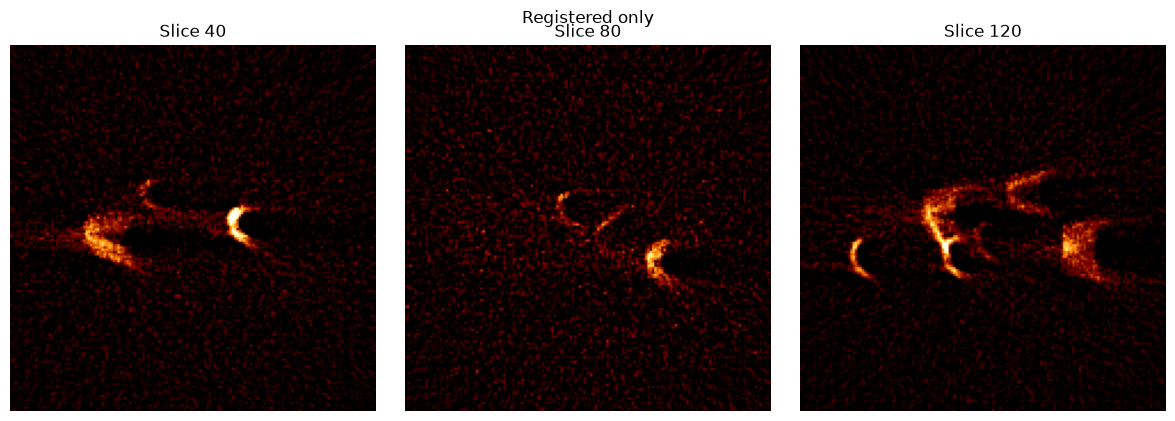

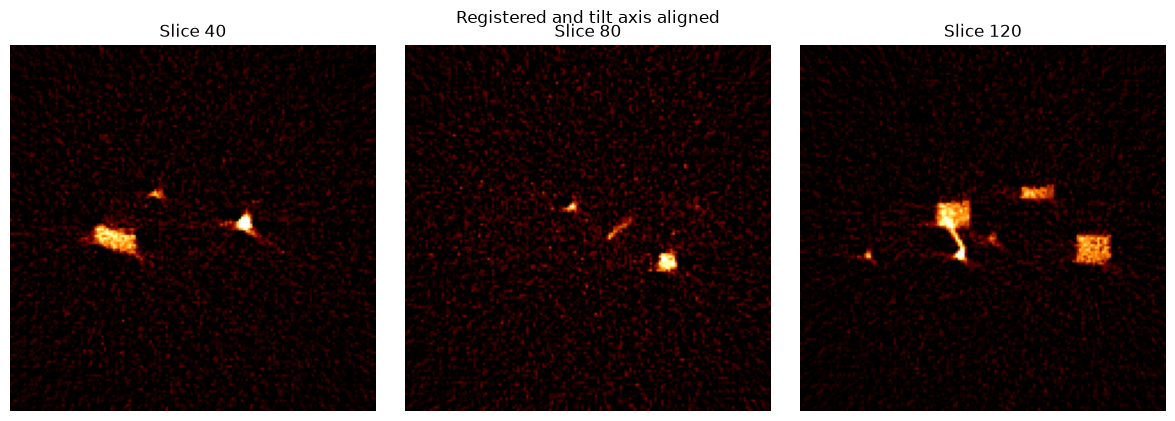

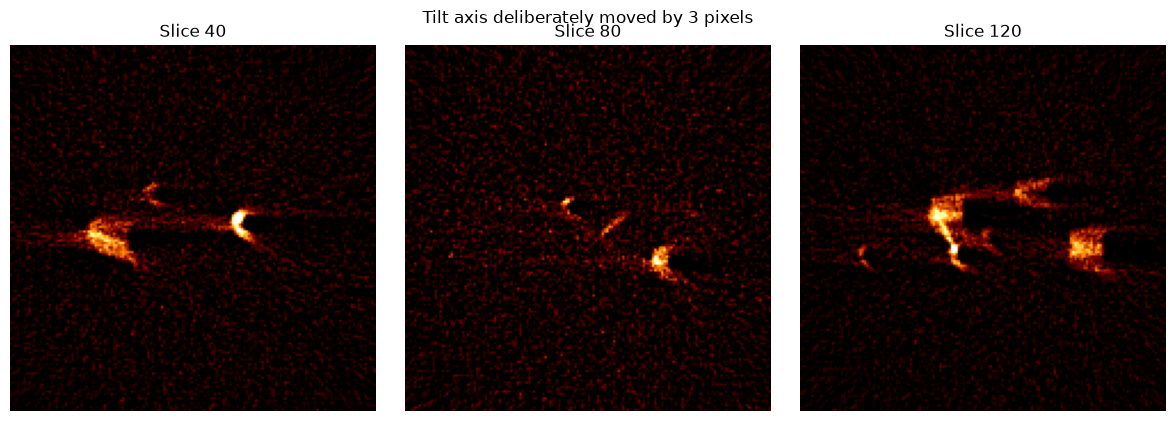

In [56]:
f = reg.test_align(slices=[40, 80, 120])
f.suptitle("Registered only", y=1.04)
f = ali.test_align(slices=[40, 80, 120])
f.suptitle("Registered and tilt axis aligned", y=1.04)
f = ali.test_align(slices=[40, 80, 120], tilt_shift=3)
f.suptitle("Tilt axis deliberately moved by 3 pixels", y=1.04)

## Repairing a Jump with `manual_align`

Sometimes a series contains a sudden jump which can cause stack_registration to fail across the discontinuity. 
`manual_align(nslice, xshift, yshift)` shifts all of the projections
from `nslice` onwards by a whole number of pixels relative to those before it, and crops the stack
to the overlap. Here we add a jump of 10 pixels to the ideal (noise-free) series, and remove it
again; the jump shows as a break in the sinogram:

INFO | Hyperspy | <Signal2D, title: , dimensions: (1|160, 90)> data is replaced by its optimized copy, see optimize parameter of ``Basesignal.transpose`` for more information. (hyperspy.signal:4241)
INFO | Hyperspy | <Signal2D, title: , dimensions: (1|150, 90)> data is replaced by its optimized copy, see optimize parameter of ``Basesignal.transpose`` for more information. (hyperspy.signal:4241)
shape before: (90, 160, 160)  after: (90, 150, 160)


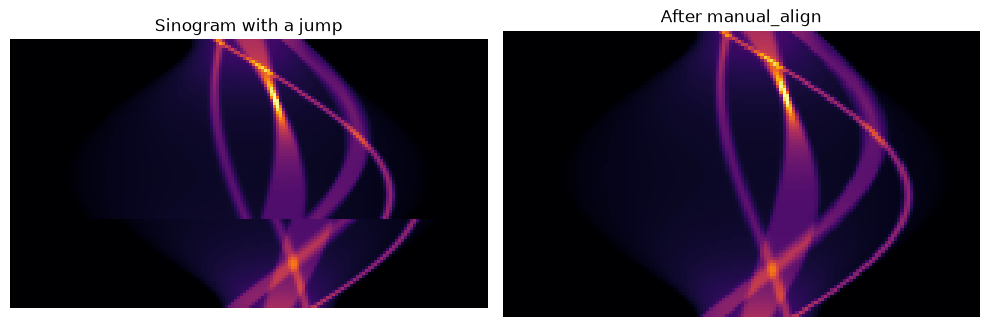

In [57]:
jumped = series.aligned.remove_background()
j = 60
jumped.data[j:] = np.roll(jumped.data[j:], 10, axis=1)         # 10 px jump in Y from projection 60
fixed = jumped.manual_align(j, yshift=-10)

hs.plot.plot_images(
    [jumped.extract_sinogram(80), fixed.extract_sinogram(80)],
    per_row=2, cmap="inferno", axes_decor="off", colorbar=None,
    label=["Sinogram with a jump", "After manual_align"],
)
plt.gcf().set_size_inches(10, 4)
plt.tight_layout()
print("shape before:", jumped.data.shape, " after:", fixed.data.shape)

## Aligning a Second Signal with `align_other`

Many tilt series record several signals at once, for example HAADF and bright-field STEM images,
or a spectrum image alongside an image. The signals share the same specimen motion, so the
alignment found on the best one (here the HAADF-like series) can be applied to the others with
`align_other`: it applies the shifts, the tilt axis shift and the rotation in the same order.
The images below show the minimum image over all projections, which is sharp only when the series is
aligned.

As a second signal we appoximate a bright-field image of the same series by taking an exponential transform
of the input dark-field simulation.

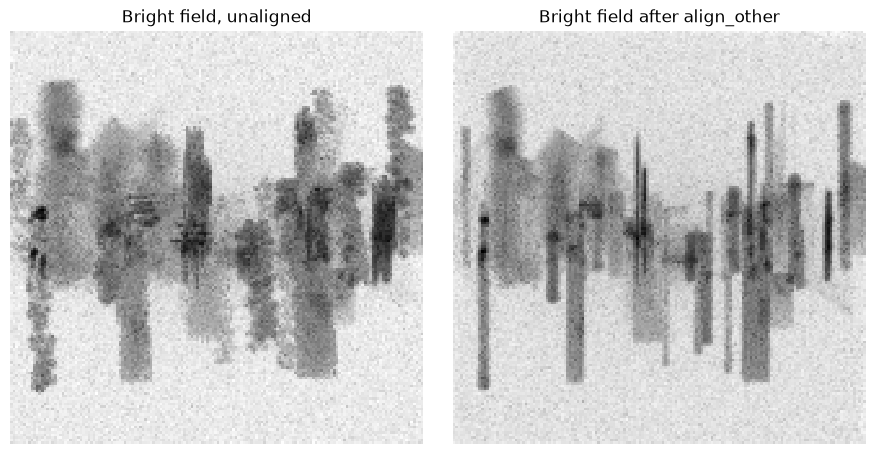

In [58]:
bright_field = stack.deepcopy()
bright_field.data = np.exp(-2 * stack.data / stack.data.max())

bf_aligned = ali.align_other(bright_field)

hs.plot.plot_images(
    [bright_field.min(), bf_aligned.min()],
    per_row=2, cmap="gray", axes_decor="off", colorbar=None,
    label=["Bright field, unaligned", "Bright field after align_other"],
)
plt.gcf().set_size_inches(9, 4.5)
plt.tight_layout()

## Reducing Interpolation Effects

The same `align_other` method can be used to apply a full calculated tranformation (stack registration plus tilt axis correction)
in one step.  This can be used to reduce the iterative interpolation effects which compound when multiple alignment steps are used.

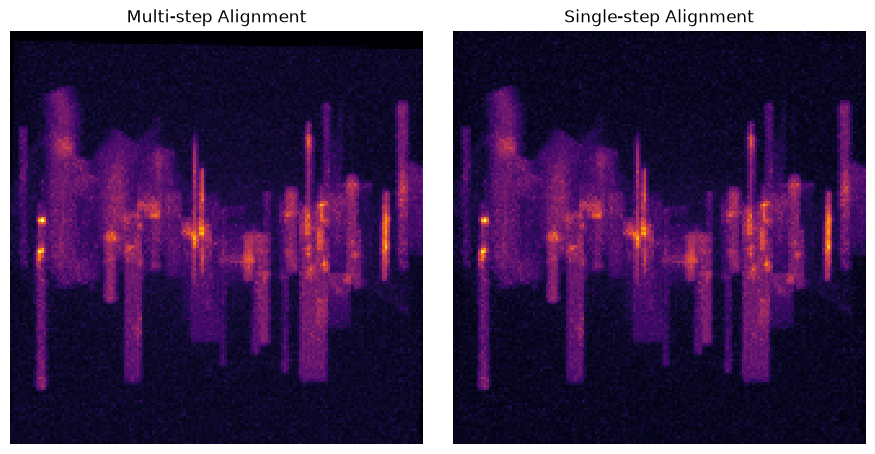

In [65]:
final = ali.align_other(stack)

hs.plot.plot_images(
    [ali.max(), final.max()],
    per_row=2, cmap="inferno", axes_decor="off", colorbar=None,
    label=["Multi-step Alignment", "Single-step Alignment"],
)
plt.gcf().set_size_inches(9, 4.5)
plt.tight_layout()

## Summary

* Register with `"StackReg"` or `"PC"` for general specimens, `"COM-CL"` for isolated objects that
  stay in view
* Then find the tilt axis with `tilt_align("CoM")` (or `"MaxImage"`), and check with `test_align`
* For deep sub-pixel accuracy, refine with [projection matching](projection_matching_demo.ipynb)
* Align the best signal, and apply the result to the others with `align_other`